In [15]:
!pip -q install -U transformers accelerate scikit-learn pandas matplotlib seaborn

In [16]:
import os
import random
import zipfile
import numpy as np
import pandas as pd
import torch

SEED = 42

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(SEED)

if not torch.cuda.is_available():
    raise RuntimeError("GPU not detected. In Colab, select Runtime > Change runtime type > T4 GPU.")

print("GPU:", torch.cuda.get_device_name(0))
print("PyTorch:", torch.__version__)

GPU: Tesla T4
PyTorch: 2.14.1+cu130


In [17]:
from google.colab import files

uploaded = files.upload()  # Select final_climate_stance_dataset_package.zip
zip_name = next((name for name in uploaded if name.lower().endswith(".zip")), None)

if zip_name is None:
    raise FileNotFoundError("Please upload the dataset ZIP file.")

DATA_DIR = "/content/climate_stance_data"
os.makedirs(DATA_DIR, exist_ok=True)

with zipfile.ZipFile(zip_name, "r") as zf:
    zf.extractall(DATA_DIR)

TRAIN_PATH = os.path.join(DATA_DIR, "final_train.csv")
VAL_PATH = os.path.join(DATA_DIR, "final_validation.csv")

if not os.path.exists(TRAIN_PATH) or not os.path.exists(VAL_PATH):
    raise FileNotFoundError("The ZIP must contain final_train.csv and final_validation.csv.")

print("Dataset extracted to:", DATA_DIR)

Saving final_climate_stance_dataset_package.zip to final_climate_stance_dataset_package (1).zip
Dataset extracted to: /content/climate_stance_data


In [18]:
train_df = pd.read_csv(TRAIN_PATH)
val_df = pd.read_csv(VAL_PATH)

required_columns = {"text", "label", "language", "split", "original_id"}
for name, frame in [("train", train_df), ("validation", val_df)]:
    missing = required_columns - set(frame.columns)
    if missing:
        raise ValueError(f"{name} file is missing columns: {missing}")

# Blank/NaN labels in these supplied files mean the None class.
for frame in (train_df, val_df):
    frame["label"] = frame["label"].fillna("None").astype(str).str.strip()
    frame["text"] = frame["text"].fillna("").astype(str)
    frame["language"] = frame["language"].astype(str).str.strip()
    frame["split"] = frame["split"].astype(str).str.strip()

label2id = {"Against": 0, "Favour": 1, "None": 2}
id2label = {v: k for k, v in label2id.items()}

for name, frame, expected_split in [
    ("train", train_df, "train"),
    ("validation", val_df, "validation")
]:
    unknown = set(frame["label"].unique()) - set(label2id)
    if unknown:
        raise ValueError(f"Unexpected labels in {name}: {unknown}")
    if set(frame["split"].unique()) != {expected_split}:
        raise ValueError(f"{name} file contains unexpected split values: {frame['split'].unique()}")
    frame["label_id"] = frame["label"].map(label2id).astype(int)

overlap = set(train_df["original_id"].dropna()) & set(val_df["original_id"].dropna())
print("Train shape:", train_df.shape)
print("Validation shape:", val_df.shape)
print("Original IDs shared between train and validation:", len(overlap))
assert len(overlap) == 0, "Data leakage check failed: original_id overlap detected."

print("\nTraining labels:")
print(train_df["label"].value_counts().reindex(["None", "Favour", "Against"]))
print("\nValidation labels:")
print(val_df["label"].value_counts().reindex(["None", "Favour", "Against"]))
print("\nTraining languages:")
print(train_df["language"].value_counts())
print("\nValidation languages:")
print(val_df["language"].value_counts())

Train shape: (4836, 8)
Validation shape: (1209, 8)
Original IDs shared between train and validation: 0

Training labels:
label
None       2118
Favour     2043
Against     675
Name: count, dtype: int64

Validation labels:
label
None       528
Favour     513
Against    168
Name: count, dtype: int64

Training languages:
language
English    1612
Hindi      1612
Bengali    1612
Name: count, dtype: int64

Validation languages:
language
English    403
Hindi      403
Bengali    403
Name: count, dtype: int64


In [19]:
class_counts = train_df["label_id"].value_counts().reindex(range(len(label2id)), fill_value=0)
num_classes = len(label2id)
total_train = len(train_df)

class_weights = total_train / (num_classes * class_counts.values)
class_weights = torch.tensor(class_weights, dtype=torch.float32)

print("Class mapping:", label2id)
print("Training counts by ID:", class_counts.to_dict())
print("Class weights (Against, Favour, None):", class_weights.tolist())

Class mapping: {'Against': 0, 'Favour': 1, 'None': 2}
Training counts by ID: {0: 675, 1: 2043, 2: 2118}
Class weights (Against, Favour, None): [2.388148069381714, 0.7890357375144958, 0.7610953450202942]


In [20]:
from transformers import AutoTokenizer

MODEL_NAME = "google/muril-base-cased"
MAX_LENGTH = 128
BATCH_SIZE = 8
EVAL_BATCH_SIZE = 16
LEARNING_RATE = 2e-5
EPOCHS = 5
PATIENCE = 2

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

train_encodings = tokenizer(
    train_df["text"].tolist(),
    truncation=True,
    padding="max_length",
    max_length=MAX_LENGTH
)
val_encodings = tokenizer(
    val_df["text"].tolist(),
    truncation=True,
    padding="max_length",
    max_length=MAX_LENGTH
)

print("Tokenizer:", MODEL_NAME)
print("Training examples tokenized:", len(train_encodings["input_ids"]))

Tokenizer: google/muril-base-cased
Training examples tokenized: 4836


## 7. Create PyTorch datasets and data loaders

In [21]:
from torch.utils.data import Dataset, DataLoader

class StanceDataset(Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = labels

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        item = {
            key: torch.tensor(values[idx], dtype=torch.long)
            for key, values in self.encodings.items()
        }
        item["labels"] = torch.tensor(int(self.labels[idx]), dtype=torch.long)
        return item

train_dataset = StanceDataset(train_encodings, train_df["label_id"].tolist())
val_dataset = StanceDataset(val_encodings, val_df["label_id"].tolist())

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True
)
val_loader = DataLoader(
    val_dataset, batch_size=EVAL_BATCH_SIZE, shuffle=False
)

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Train batches: 605
Validation batches: 76


In [22]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)

def calculate_metrics(y_true, y_pred):
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision_macro": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "recall_macro": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "macro_f1": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "weighted_f1": f1_score(y_true, y_pred, average="weighted", zero_division=0),
    }

@torch.no_grad()
def predict_model(model, loader):
    model.eval()
    all_labels, all_preds = [], []

    for batch in loader:
        batch = {k: v.to(device) for k, v in batch.items()}
        labels = batch.pop("labels")
        with torch.cuda.amp.autocast(enabled=USE_AMP):
            outputs = model(**batch)
        preds = torch.argmax(outputs.logits, dim=1)

        all_labels.extend(labels.cpu().numpy().tolist())
        all_preds.extend(preds.cpu().numpy().tolist())

    return np.array(all_labels), np.array(all_preds)

In [23]:
from transformers import AutoModelForSequenceClassification, get_linear_schedule_with_warmup
from torch.optim import AdamW
from tqdm.auto import tqdm
import copy

device = torch.device("cuda")
USE_AMP = True

def train_model(run_name="muril_weighted", use_class_weights=True):
    set_seed(SEED)

    model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME,
        num_labels=3,
        id2label=id2label,
        label2id=label2id
    ).to(device)

    weights = class_weights.to(device) if use_class_weights else None
    criterion = torch.nn.CrossEntropyLoss(weight=weights)

    optimizer = AdamW(model.parameters(), lr=LEARNING_RATE)
    total_steps = len(train_loader) * EPOCHS
    scheduler = get_linear_schedule_with_warmup(
        optimizer,
        num_warmup_steps=int(0.1 * total_steps),
        num_training_steps=total_steps
    )

    scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)
    best_macro_f1 = -1.0
    best_epoch = 0
    epochs_without_improvement = 0
    history = []

    output_dir = f"/content/{run_name}_best"
    os.makedirs(output_dir, exist_ok=True)

    for epoch in range(EPOCHS):
        model.train()
        running_loss = 0.0

        progress = tqdm(train_loader, desc=f"{run_name} | Epoch {epoch+1}/{EPOCHS}")
        for batch in progress:
            batch = {k: v.to(device) for k, v in batch.items()}
            labels = batch.pop("labels")

            optimizer.zero_grad(set_to_none=True)

            with torch.cuda.amp.autocast(enabled=USE_AMP):
                outputs = model(**batch)
                loss = criterion(outputs.logits, labels)

            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()

            running_loss += loss.item()
            progress.set_postfix(loss=f"{loss.item():.4f}")

        y_true, y_pred = predict_model(model, val_loader)
        metrics = calculate_metrics(y_true, y_pred)
        avg_train_loss = running_loss / len(train_loader)

        row = {"epoch": epoch + 1, "train_loss": avg_train_loss, **metrics}
        history.append(row)

        print(f"\nEpoch {epoch+1}: train_loss={avg_train_loss:.4f}, "
              f"validation_macro_f1={metrics['macro_f1']:.4f}")

        if metrics["macro_f1"] > best_macro_f1:
            best_macro_f1 = metrics["macro_f1"]
            best_epoch = epoch + 1
            epochs_without_improvement = 0

            model.save_pretrained(output_dir)
            tokenizer.save_pretrained(output_dir)
            print("Saved new best checkpoint:", output_dir)
        else:
            epochs_without_improvement += 1

        if epochs_without_improvement >= PATIENCE:
            print("Early stopping: validation Macro F1 did not improve.")
            break

    print(f"Best epoch: {best_epoch}; best validation Macro F1: {best_macro_f1:.4f}")
    del model
    torch.cuda.empty_cache()

    best_model = AutoModelForSequenceClassification.from_pretrained(output_dir).to(device)
    return best_model, pd.DataFrame(history), output_dir

weighted_model, weighted_history, WEIGHTED_MODEL_DIR = train_model(
    run_name="muril_weighted",
    use_class_weights=True
)

display(weighted_history)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: google/muril-base-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params w

muril_weighted | Epoch 1/5:   0%|          | 0/605 [00:00<?, ?it/s]

/tmp/ipykernel_514/48952492.py:50: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=USE_AMP):
/tmp/ipykernel_514/2510983662.py:23: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=USE_AMP):



Epoch 1: train_loss=1.0933, validation_macro_f1=0.4655


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (17 outputs left out)

/tmp/ipykernel_514/48952492.py:50: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=USE_AMP):
/tmp/ipykernel_514/2510983662.py:23: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=USE_AMP):



Epoch 5: train_loss=0.2914, validation_macro_f1=0.7211
Best epoch: 4; best validation Macro F1: 0.7244


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

,epoch,train_loss,accuracy,precision_macro,recall_macro,macro_f1,weighted_f1
0,1,1.093308,0.580645,0.632275,0.471934,0.465502,0.551882
1,2,0.931782,0.703060,0.673426,0.721815,0.681720,0.710311
2,3,0.613676,0.751034,0.716811,0.735003,0.724091,0.752441
3,4,0.397411,0.760132,0.745735,0.710667,0.724411,0.757516
4,5,0.291367,0.750207,0.715997,0.727497,0.721102,0.751208


In [24]:
weighted_y_true, weighted_y_pred = predict_model(weighted_model, val_loader)

print("OVERALL VALIDATION METRICS — WEIGHTED MuRIL")
print(pd.Series(calculate_metrics(weighted_y_true, weighted_y_pred)).round(4))

print("\nCLASSIFICATION REPORT")
print(classification_report(
    weighted_y_true,
    weighted_y_pred,
    labels=[0, 1, 2],
    target_names=[id2label[i] for i in range(3)],
    digits=4,
    zero_division=0
))

weighted_cm = confusion_matrix(weighted_y_true, weighted_y_pred, labels=[0, 1, 2])
print("Confusion matrix (true rows × predicted columns):")
print(pd.DataFrame(
    weighted_cm,
    index=[f"True {id2label[i]}" for i in range(3)],
    columns=[f"Pred {id2label[i]}" for i in range(3)]
))

/tmp/ipykernel_514/2510983662.py:23: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=USE_AMP):


OVERALL VALIDATION METRICS — WEIGHTED MuRIL
accuracy           0.7593
precision_macro    0.7445
recall_macro       0.7087
macro_f1           0.7226
weighted_f1        0.7566
dtype: float64

CLASSIFICATION REPORT
              precision    recall  f1-score   support

     Against     0.6977    0.5357    0.6061       168
      Favour     0.7890    0.7797    0.7843       513
        None     0.7469    0.8106    0.7775       528

    accuracy                         0.7593      1209
   macro avg     0.7445    0.7087    0.7226      1209
weighted avg     0.7579    0.7593    0.7566      1209

Confusion matrix (true rows × predicted columns):
              Pred Against  Pred Favour  Pred None
True Against            90           33         45
True Favour             13          400        100
True None               26           74        428


## Evaluate separately for English, Hindi and Bengali



In [25]:
language_results = []

for language in ["English", "Hindi", "Bengali"]:
    indices = np.where(val_df["language"].to_numpy() == language)[0]
    y_true_lang = weighted_y_true[indices]
    y_pred_lang = weighted_y_pred[indices]
    metrics = calculate_metrics(y_true_lang, y_pred_lang)
    metrics["language"] = language
    metrics["n"] = len(indices)
    language_results.append(metrics)

language_results_df = pd.DataFrame(language_results).set_index("language")
display(language_results_df.round(4))

for language in ["English", "Hindi", "Bengali"]:
    indices = np.where(val_df["language"].to_numpy() == language)[0]
    print(f"\n{language} classification report")
    print(classification_report(
        weighted_y_true[indices],
        weighted_y_pred[indices],
        labels=[0, 1, 2],
        target_names=[id2label[i] for i in range(3)],
        digits=4,
        zero_division=0
    ))

,accuracy,precision_macro,recall_macro,macro_f1,weighted_f1,n
language,,,,,,
English,0.7692,0.7502,0.7285,0.7377,0.7678,403
Hindi,0.7444,0.7337,0.6891,0.7054,0.7409,403
Bengali,0.7643,0.7505,0.7084,0.7240,0.7608,403



English classification report
              precision    recall  f1-score   support

     Against     0.6875    0.5893    0.6346        56
      Favour     0.8024    0.7836    0.7929       171
        None     0.7606    0.8125    0.7857       176

    accuracy                         0.7692       403
   macro avg     0.7502    0.7285    0.7377       403
weighted avg     0.7682    0.7692    0.7678       403


Hindi classification report
              precision    recall  f1-score   support

     Against     0.7000    0.5000    0.5833        56
      Favour     0.7719    0.7719    0.7719       171
        None     0.7292    0.7955    0.7609       176

    accuracy                         0.7444       403
   macro avg     0.7337    0.6891    0.7054       403
weighted avg     0.7433    0.7444    0.7409       403


Bengali classification report
              precision    recall  f1-score   support

     Against     0.7073    0.5179    0.5979        56
      Favour     0.7929    0.7836    0

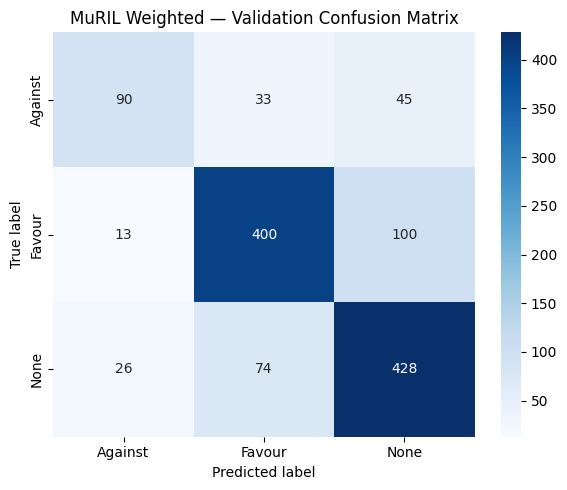

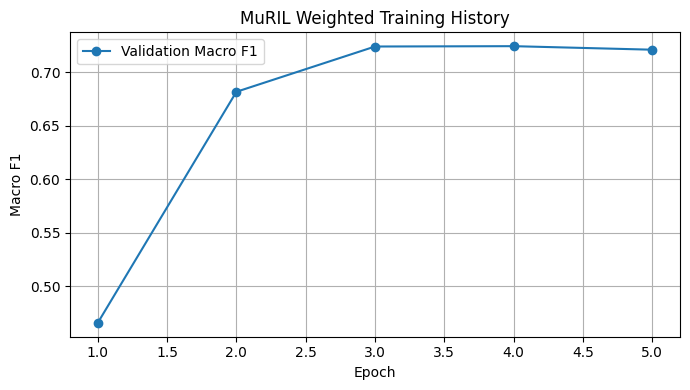

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6, 5))
sns.heatmap(
    weighted_cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=[id2label[i] for i in range(3)],
    yticklabels=[id2label[i] for i in range(3)]
)
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.title("MuRIL Weighted — Validation Confusion Matrix")
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(weighted_history["epoch"], weighted_history["macro_f1"], marker="o", label="Validation Macro F1")
plt.xlabel("Epoch")
plt.ylabel("Macro F1")
plt.title("MuRIL Weighted Training History")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

In [27]:
# Save predictions with original validation information
prediction_df = val_df[["text", "label", "language", "original_id"]].copy()
prediction_df["true_label"] = [id2label[i] for i in weighted_y_true]
prediction_df["predicted_label"] = [id2label[i] for i in weighted_y_pred]
prediction_df.to_csv("/content/muril_validation_predictions.csv", index=False)

language_results_df.to_csv("/content/muril_language_wise_metrics.csv")
weighted_history.to_csv("/content/muril_training_history.csv", index=False)

overall_metrics_df = pd.DataFrame([calculate_metrics(weighted_y_true, weighted_y_pred)])
overall_metrics_df.to_csv("/content/muril_overall_metrics.csv", index=False)

pd.DataFrame(
    weighted_cm,
    index=[f"True_{id2label[i]}" for i in range(3)],
    columns=[f"Pred_{id2label[i]}" for i in range(3)]
).to_csv("/content/muril_confusion_matrix.csv")

# Save the best model and tokenizer to a ZIP file
import shutil
MODEL_ZIP_BASE = "/content/muril_weighted_best"
shutil.make_archive(MODEL_ZIP_BASE, "zip", WEIGHTED_MODEL_DIR)

print("Saved model directory:", WEIGHTED_MODEL_DIR)
print("Saved model archive:", MODEL_ZIP_BASE + ".zip")

Saved model directory: /content/muril_weighted_best
Saved model archive: /content/muril_weighted_best.zip


In [28]:
from google.colab import files
files.download("/content/muril_weighted_best.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>